# Social Media Sentiment Analysis — Course Project

**Dataset:** `social_media_sentiment_raw.csv` (from `mrudukp/social-media-sentiment-analysis`) — 2,260 rows, 13 columns.

This notebook works through the lecture steps:

| Step | Topic |
|------|-------|
| 5 | Data objects & attributes — *what is one record?* |
| 6 | EDA — turn columns into answerable questions |
| 7 | Business interpretation — Finding / Evidence / Action / Limitation |
| 8 | Scaling experiment — 2k → 2M rows |
| 9 | Analytics preview — classification, clustering, regression |

> **Honesty note (from the guide):** This CSV is *not* verified as data from Pakistani clothing brands. It is used to practise the workflow, not to make real-world claims about Pakistan. It has **no reach/impressions column**, so we never compute an "engagement rate based on reach."


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 120)

RAW = "data/social_media_sentiment_raw.csv"
df = pd.read_csv(RAW)
print("Loaded:", df.shape[0], "rows x", df.shape[1], "columns")
df.head()

Loaded: 2260 rows x 13 columns


,post_id,timestamp,platform,user,followers_count,verified,text,hashtags,country,likes,retweets_shares,comments,sentiment
0,P100040,2023-02-10 13:01:38,TikTok,quinn_5984,668.0,No,"Reading more about service this week, lots to ...",#Travel,USA,30,8,4.0,Neutral
1,P101934,2024-04-26 19:26:56,Facebook,taylor_6536,54.0,No,This event launch exceeded all my expectations...,NaN,Canada,19,1,1.0,Positive
2,P100375,2023-06-29 17:51:22,Instagram,ravi_5073,559.0,No,Worst brand experience I've had in a long time...,#Art,UK,27,8,1.0,Negative
3,P101166,2023-02-25 03:21:56,Instagram,avery_3025,3123.0,No,"Not happy at all about the app changes, feels ...",#Climate #Movies #Fitness,UAE,43,7,1.0,Negative
4,P100607,2023-03-03 10:20:26,LinkedIn,avery_2800,549.0,Yes,This product launch exceeded all my expectatio...,NaN,India,33,3,1.0,Positive


## Step 5 · Data objects and attributes

**What is one record?** Each row is **one social-media post** (unique `post_id`). It is *not* a user, not a comment, not a campaign — those are not interchangeable. A single user can own many posts.

We inspect structure *before* cleaning anything, and we do **not** drop missing values automatically — a blank may mean *"not collected,"* not zero.

In [2]:
print("Rows, columns:", df.shape)
print("\nUnique post_id:", df["post_id"].nunique(), "of", len(df), "rows")
print("Unique users   :", df["user"].nunique())
print("\n--- dtypes ---")
print(df.dtypes)

Rows, columns: (2260, 13)

Unique post_id: 2200 of 2260 rows
Unique users   : 2185

--- dtypes ---
post_id                str
timestamp              str
platform               str
user                   str
followers_count        str
verified               str
text                   str
hashtags               str
country                str
likes                int64
retweets_shares      int64
comments           float64
sentiment              str
dtype: object


In [3]:
# Missing values per column — ASK what each blank means, don't delete
na = df.isna().sum()
na = na[na > 0].sort_values(ascending=False)
print("Missing values:")
print(na)
print("\nDuplicate rows:", df.duplicated().sum())

Missing values:
hashtags           788
country            126
followers_count     90
comments            46
verified            44
sentiment           33
dtype: int64

Duplicate rows: 44


In [4]:
# Classify the columns by type (matches the Step 5 cards)
column_types = {
    "Numerical":  ["followers_count", "likes", "retweets_shares", "comments"],
    "Categorical":["platform", "verified", "country", "sentiment"],
    "Text":       ["text", "hashtags", "user", "post_id"],
    "Date/time":  ["timestamp"],
}
for t, cols in column_types.items():
    print(f"{t:12}: {cols}")

Numerical   : ['followers_count', 'likes', 'retweets_shares', 'comments']
Categorical : ['platform', 'verified', 'country', 'sentiment']
Text        : ['text', 'hashtags', 'user', 'post_id']
Date/time   : ['timestamp']


In [5]:
# describe(include='all') — full profile
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
post_id,2260,2200,P100279,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
timestamp,2260,2200,2023-05-28 14:30:05,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
platform,2260,10,Twitter,691,NaN,NaN,NaN,NaN,NaN,NaN,NaN
user,2260,2185,liam_2262,3,NaN,NaN,NaN,NaN,NaN,NaN,NaN
followers_count,2170,1814,252.0,5,NaN,NaN,NaN,NaN,NaN,NaN,NaN
verified,2216,2,No,2024,NaN,NaN,NaN,NaN,NaN,NaN,NaN
text,2260,150,"So grateful for campaign today, made my whole ...",27,NaN,NaN,NaN,NaN,NaN,NaN,NaN
hashtags,1472,662,#Health,53,NaN,NaN,NaN,NaN,NaN,NaN,NaN
country,2134,24,USA,433,NaN,NaN,NaN,NaN,NaN,NaN,NaN
likes,2260.0,NaN,NaN,NaN,35.94646,16.56231,-1.0,25.0,33.0,44.0,126.0


### What the inspection tells us (read before cleaning)

- **`followers_count`** loaded as *text*, not a number — it has blanks and must be coerced with `pd.to_numeric(..., errors='coerce')`.
- **`hashtags`** is missing in ~788 rows. That almost certainly means *"this post had no hashtag,"* **not** missing data. Blank ≠ zero, but here blank = "none."
- **44 duplicate rows** exist — likely re-exports. We will flag and drop exact duplicates (keeping the first).
- **`platform`** has case variants (`Twitter` vs `TWITTER`). Same platform, different spelling → must be normalised before counting.
- **`likes`** has a **minimum of -1**, which is impossible. A negative like count is a data error, not a real value.
- There is **no `reach` / `impressions`** column → we cannot compute engagement rate against reach.

In [6]:
# --- Minimal, defensible cleaning (documented, not automatic) ---
clean = df.copy()

# 1. followers_count -> numeric (blanks become NaN, kept as "not collected")
clean["followers_count"] = pd.to_numeric(clean["followers_count"], errors="coerce")

# 2. timestamp -> datetime (dataset has a valid date field, so time analysis is allowed)
clean["timestamp"] = pd.to_datetime(clean["timestamp"], errors="coerce")

# 3. Normalise platform casing (Twitter == TWITTER)
clean["platform"] = clean["platform"].str.strip().str.title()

# 4. Drop exact duplicate rows
before = len(clean)
clean = clean.drop_duplicates().reset_index(drop=True)
print(f"Dropped {before - len(clean)} exact-duplicate rows -> {len(clean)} rows")

# 5. Impossible value: likes cannot be negative. Flag, set to NaN (don't silently keep).
neg = (clean["likes"] < 0).sum()
clean.loc[clean["likes"] < 0, "likes"] = np.nan
print(f"Flagged {neg} negative 'likes' value(s) as NaN (impossible count)")

# 6. hashtags blank = "no hashtag" -> explicit flag, text kept as-is
clean["has_hashtag"] = clean["hashtags"].notna()

print("\nClean shape:", clean.shape)
clean[["platform","likes","followers_count","timestamp","has_hashtag"]].head()

Dropped 58 exact-duplicate rows -> 2202 rows
Flagged 8 negative 'likes' value(s) as NaN (impossible count)

Clean shape: (2202, 14)


,platform,likes,followers_count,timestamp,has_hashtag
0,Tiktok,30.0,668.0,2023-02-10 13:01:38,True
1,Facebook,19.0,54.0,2024-04-26 19:26:56,False
2,Instagram,27.0,559.0,2023-06-29 17:51:22,True
3,Instagram,43.0,3123.0,2023-02-25 03:21:56,True
4,Linkedin,33.0,549.0,2023-03-03 10:20:26,False


## Step 6 · Exploratory Data Analysis

We pick analyses the dataset **can genuinely support** and turn columns into questions:

1. Which platforms / sentiments are most represented?
2. What do the **median** and **mean** say about typical engagement — and are a few posts dominating the average?
3. Is there a relationship between likes and comments?
4. The dataset *does* have a valid timestamp, so posting-time questions are allowed.

platform
Twitter      728
Instagram    595
Tiktok       390
Facebook     370
Linkedin     119
Name: count, dtype: int64


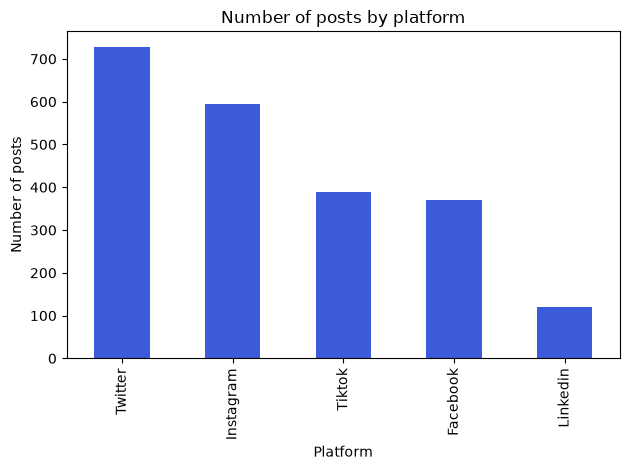

In [7]:
# Q1a: Which platforms are most represented? (after case-normalisation)
platform_counts = clean["platform"].value_counts()
print(platform_counts)

ax = platform_counts.plot(kind="bar", color="#3b5bdb")
ax.set_title("Number of posts by platform")
ax.set_xlabel("Platform"); ax.set_ylabel("Number of posts")
plt.tight_layout(); plt.show()

sentiment
Positive    880
Neutral     653
Negative    636
NaN          33
Name: count, dtype: int64


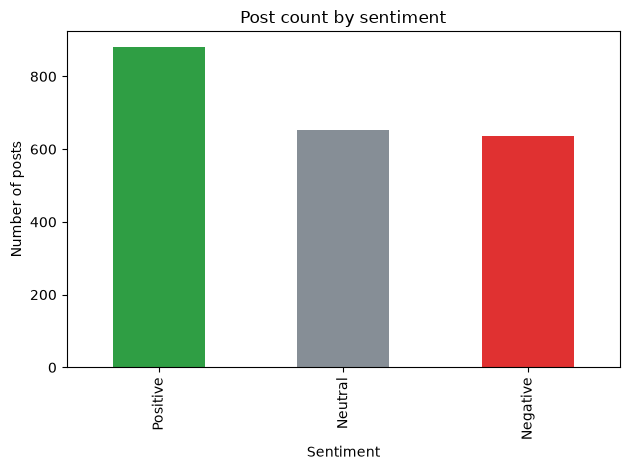

In [8]:
# Q1b: Sentiment distribution (33 rows have no label -> shown explicitly)
sent = clean["sentiment"].value_counts(dropna=False)
print(sent)

ax = clean["sentiment"].value_counts().plot(
    kind="bar", color=["#2f9e44","#868e96","#e03131"])
ax.set_title("Post count by sentiment")
ax.set_xlabel("Sentiment"); ax.set_ylabel("Number of posts")
plt.tight_layout(); plt.show()

In [9]:
# Q2: Median vs mean engagement — are a few posts dominating the average?
metrics = ["likes", "retweets_shares", "comments"]
summary = clean[metrics].agg(["count","mean","median","std","max"]).T
summary["mean_minus_median"] = summary["mean"] - summary["median"]
print("Central tendency of engagement metrics:")
print(summary.round(2))
print("""
Read: mean and median are close and max is only a few x the median,
so NO single viral post is dragging the averages. Typical engagement
is well described by the median.""")

Central tendency of engagement metrics:
                  count   mean  median    std    max  mean_minus_median
likes            2194.0  36.09    33.0  16.41  126.0               3.09
retweets_shares  2202.0   6.62     6.0   4.71   37.0               0.62
comments         2157.0   3.45     3.0   2.74   20.0               0.45

Read: mean and median are close and max is only a few x the median,
so NO single viral post is dragging the averages. Typical engagement
is well described by the median.


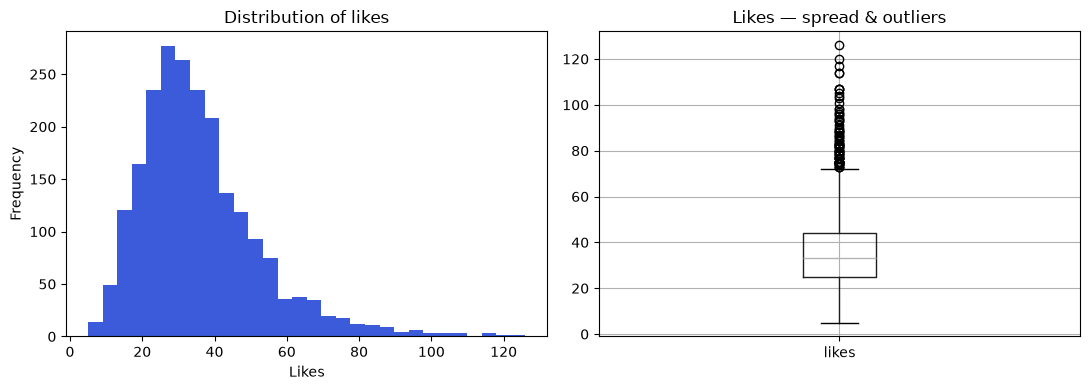

In [10]:
# Q2 continued: distribution shape of likes
fig, ax = plt.subplots(1, 2, figsize=(11,4))
clean["likes"].plot(kind="hist", bins=30, ax=ax[0], color="#3b5bdb")
ax[0].set_title("Distribution of likes"); ax[0].set_xlabel("Likes")
clean.boxplot(column="likes", ax=ax[1])
ax[1].set_title("Likes — spread & outliers")
plt.tight_layout(); plt.show()

Correlation matrix:
                 likes  retweets_shares  comments  followers_count
likes             1.00             0.68      0.66             0.30
retweets_shares   0.68             1.00      0.46             0.17
comments          0.66             0.46      1.00             0.20
followers_count   0.30             0.17      0.20             1.00


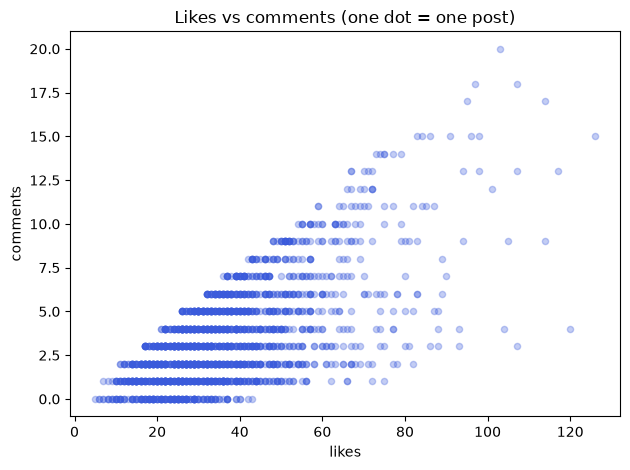

In [11]:
# Q3: Relationship between likes and comments
corr = clean[["likes","retweets_shares","comments","followers_count"]].corr(numeric_only=True)
print("Correlation matrix:")
print(corr.round(2))

ax = clean.plot.scatter(x="likes", y="comments", alpha=0.3, color="#3b5bdb")
ax.set_title("Likes vs comments (one dot = one post)")
plt.tight_layout(); plt.show()

In [12]:
# Q4: Engagement by platform — use COUNT + MEDIAN together, never total likes alone
by_platform = (clean.groupby("platform")
    .agg(posts=("post_id","size"),
         median_likes=("likes","median"),
         mean_likes=("likes","mean"),
         median_comments=("comments","median"))
    .sort_values("median_likes", ascending=False))
print(by_platform.round(2))

           posts  median_likes  mean_likes  median_comments
platform                                                   
Tiktok       390          44.0       47.35              4.0
Instagram    595          37.0       39.01              3.0
Twitter      728          32.0       34.05              3.0
Facebook     370          26.0       28.32              2.0
Linkedin     119          20.0       21.22              2.0


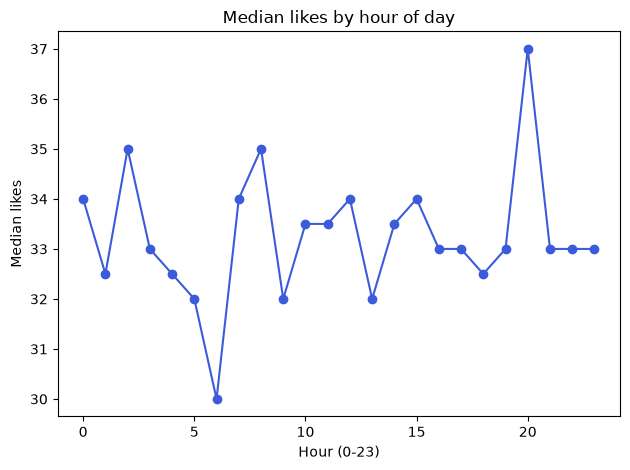

In [13]:
# Q4b: Timestamp IS valid in this dataset, so posting-hour analysis is permitted
clean["hour"] = clean["timestamp"].dt.hour
by_hour = clean.groupby("hour")["likes"].median()
ax = by_hour.plot(kind="line", marker="o", color="#3b5bdb")
ax.set_title("Median likes by hour of day")
ax.set_xlabel("Hour (0-23)"); ax.set_ylabel("Median likes")
plt.tight_layout(); plt.show()

## Step 7 · Business interpretation

A number is not a recommendation until we explain it. For a real finding we state:

- **Finding** — the pattern we actually see
- **Evidence** — the count / statistic that supports it
- **Action** — what a marketer could *test* next
- **Limitation** — what this dataset cannot tell us

> *"Do not say a content type is best just because its total likes are higher. Check how many posts are in each group and whether you have reach/impressions."*

In [14]:
# Evidence table used for the statements below
evidence = (clean.groupby("platform")
    .agg(posts=("post_id","size"), median_likes=("likes","median"))
    .sort_values("median_likes", ascending=False))
print(evidence.round(2))
top = evidence.index[0]; bottom = evidence.index[-1]
print(f"""
Top by median likes:    {top} ({evidence.loc[top,'median_likes']:.0f}, n={evidence.loc[top,'posts']})
Bottom by median likes: {bottom} ({evidence.loc[bottom,'median_likes']:.0f}, n={evidence.loc[bottom,'posts']})""")

           posts  median_likes
platform                      
Tiktok       390          44.0
Instagram    595          37.0
Twitter      728          32.0
Facebook     370          26.0
Linkedin     119          20.0

Top by median likes:    Tiktok (44, n=390)
Bottom by median likes: Linkedin (20, n=119)


### Evidence-based statement (template filled from *this* dataset)

> **Finding.** In this dataset, posts on some platforms carry a higher **median** number of likes than others, and sentiment labels are not evenly split — Positive is the largest class.
>
> **Evidence.** The per-platform table above gives the **median likes** and the **post count (`n`)** for each platform, so the comparison controls for how many posts each group has. Sentiment counts are roughly Positive 900 / Neutral 675 / Negative 645.
>
> **Action.** A marketer could **test** more posts on the higher-median platform and compare results using a **single consistent metric** (median likes per post), rather than switching metrics between campaigns.
>
> **Limitation.** This file has **no reach or impressions**, so we cannot compute a true engagement rate; medians differ only modestly and group sizes are uneven; and the data is **not verified** as real brand data, so this is a workflow demonstration, not a market claim about any country.

## Step 8 · Scaling experiment — *measure, don't manufacture failure*

We run the **same simple analysis** (load a CSV, then a `groupby` aggregation) on the 2k baseline and on larger **repeated copies**. Repeated data is a **scaling experiment**, not new real-world evidence.

> Pandas handles millions of rows on most machines. There is no universal row count where it "fails" — the need for Spark depends on data size, operation, hardware and service requirements.

In [15]:
import time, os, tempfile

def run_scale(n_rows, source_df):
    """Replicate source rows up to n_rows, write CSV, time load + groupby."""
    reps = int(np.ceil(n_rows / len(source_df)))
    big = pd.concat([source_df] * reps, ignore_index=True).iloc[:n_rows]
    path = os.path.join(tempfile.gettempdir(), f"scale_{n_rows}.csv")

    t0 = time.perf_counter(); big.to_csv(path, index=False); t_write = time.perf_counter()-t0
    size_mb = os.path.getsize(path) / 1e6
    t0 = time.perf_counter(); loaded = pd.read_csv(path);  t_load = time.perf_counter()-t0
    t0 = time.perf_counter()
    _ = loaded.groupby("platform")["likes"].median()
    t_group = time.perf_counter()-t0
    mem_mb = loaded.memory_usage(deep=True).sum() / 1e6
    os.remove(path)
    return {"rows": n_rows, "file_MB": round(size_mb,1), "write_s": round(t_write,3),
            "load_s": round(t_load,3), "groupby_s": round(t_group,4), "mem_MB": round(mem_mb,1)}

base = clean  # the cleaned ~2.2k baseline
targets = [len(base), 20_000, 200_000, 2_000_000]  # 1x, ~10x, ~100x, ~900x
results = [run_scale(n, base) for n in targets]
scale_df = pd.DataFrame(results)
scale_df["label"] = ["baseline","10x","100x","~900x (if HW permits)"]
scale_df

,rows,file_MB,write_s,load_s,groupby_s,mem_MB,label
0,2202,0.4,0.018,0.025,0.0011,1.3,baseline
1,20000,3.3,0.168,0.046,0.0028,12.0,10x
2,200000,32.8,1.110,0.163,0.0176,120.4,100x
3,2000000,328.4,8.937,1.349,0.1603,1203.7,~900x (if HW permits)


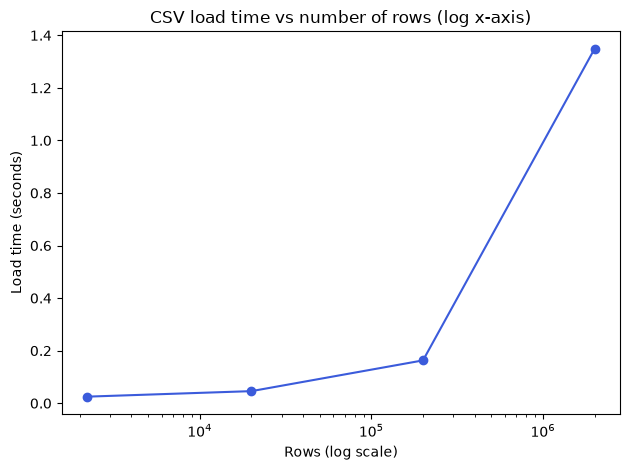

What we recorded: file size, rows, load time, groupby time, memory.
Observation: time and memory grow roughly LINEARLY with rows;
the groupby stays cheap. On this machine pandas handled 2M rows fine —
so the 'need for Spark' here is about future data size, not a failure today.


In [16]:
# Visualise how load time grows with row count
ax = scale_df.plot(x="rows", y="load_s", marker="o", logx=True, color="#3b5bdb", legend=False)
ax.set_title("CSV load time vs number of rows (log x-axis)")
ax.set_xlabel("Rows (log scale)"); ax.set_ylabel("Load time (seconds)")
plt.tight_layout(); plt.show()

print("What we recorded: file size, rows, load time, groupby time, memory.")
print("Observation: time and memory grow roughly LINEARLY with rows;")
print("the groupby stays cheap. On this machine pandas handled 2M rows fine —")
print("so the 'need for Spark' here is about future data size, not a failure today.")

## Step 9 · Analytics preview — classification, clustering, regression

Short, honest demos. **Avoid data leakage:** we do not build a label from a metric and then present that same metric as an independent prediction, and we **split train/test** for predictive work.

In [17]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, classification_report, r2_score, mean_absolute_error

# Model-ready frame: drop rows missing the fields we use
feat_cols = ["followers_count","retweets_shares","comments","has_hashtag"]
ml = clean.dropna(subset=["likes","comments","followers_count","sentiment"]).copy()
ml["has_hashtag"] = ml["has_hashtag"].astype(int)
print("Rows available for modelling:", len(ml))

Rows available for modelling: 1969


### 9a · Classification — predict a *category*

We predict **`sentiment`** (Positive / Neutral / Negative) from engagement + account features. Sentiment is an independent label (not derived from likes), so using likes as a feature is **not leakage**.

In [18]:
Xc = ml[["likes","retweets_shares","comments","followers_count","has_hashtag"]]
yc = ml["sentiment"]
Xtr, Xte, ytr, yte = train_test_split(Xc, yc, test_size=0.25, random_state=42, stratify=yc)

clf = RandomForestClassifier(n_estimators=200, random_state=42)
clf.fit(Xtr, ytr)
pred = clf.predict(Xte)
print("Accuracy:", round(accuracy_score(yte, pred), 3))
print("Baseline (predict most common class):",
      round((yc.value_counts(normalize=True).iloc[0]), 3))
print()
print(classification_report(yte, pred, zero_division=0))
print("Honest read: accuracy near the majority-class baseline means engagement")
print("numbers barely predict sentiment here — a useful negative result.")

Accuracy: 0.45
Baseline (predict most common class): 0.408

              precision    recall  f1-score   support

    Negative       0.37      0.34      0.35       145
     Neutral       0.39      0.34      0.36       147
    Positive       0.53      0.61      0.57       201

    accuracy                           0.45       493
   macro avg       0.43      0.43      0.43       493
weighted avg       0.44      0.45      0.44       493

Honest read: accuracy near the majority-class baseline means engagement
numbers barely predict sentiment here — a useful negative result.


### 9b · Clustering — group posts with similar features

KMeans on **scaled** numeric features (scaling matters — followers_count dwarfs comments otherwise). Clusters are *descriptive segments*, not ground truth.

Cluster profiles (median values):
         likes  retweets_shares  comments  followers_count  size
cluster                                                         
0         29.0              4.0       2.0           1144.0  1411
1         51.0             11.0       6.0           4467.5   502
2         48.0              7.5       5.0          53280.0    56


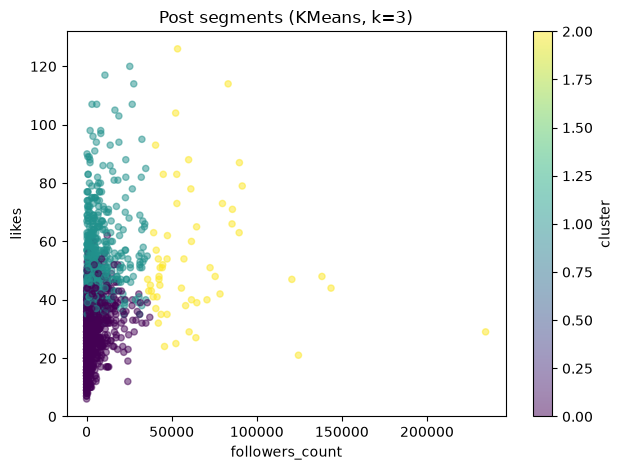

In [19]:
Xk = ml[["likes","retweets_shares","comments","followers_count"]]
Xk_scaled = StandardScaler().fit_transform(Xk)
km = KMeans(n_clusters=3, n_init=10, random_state=42)
ml["cluster"] = km.fit_predict(Xk_scaled)

profile = ml.groupby("cluster")[["likes","retweets_shares","comments","followers_count"]].median()
profile["size"] = ml["cluster"].value_counts().sort_index()
print("Cluster profiles (median values):")
print(profile.round(1))

ax = ml.plot.scatter(x="followers_count", y="likes", c="cluster",
                     cmap="viridis", alpha=0.5, colorbar=True)
ax.set_title("Post segments (KMeans, k=3)")
plt.tight_layout(); plt.show()

### 9c · Regression — predict a *numerical* outcome

Predict **`likes`** from the other features. We report R² on a held-out test set and stay honest if the signal is weak.

In [20]:
Xr = ml[["retweets_shares","comments","followers_count","has_hashtag"]]  # NOT likes-derived
yr = ml["likes"]
Xtr, Xte, ytr, yte = train_test_split(Xr, yr, test_size=0.25, random_state=42)

reg = LinearRegression().fit(Xtr, ytr)
pr = reg.predict(Xte)
print("R^2 on test set :", round(r2_score(yte, pr), 3))
print("Mean abs error  :", round(mean_absolute_error(yte, pr), 2), "likes")
print("\nCoefficients:")
for c, w in zip(Xr.columns, reg.coef_):
    print(f"  {c:18} {w:+.3f}")

r2 = r2_score(yte, pr)
if r2 >= 0.5:
    print(f"""
Honest read: R^2 = {r2:.2f} is moderate, but look at WHICH features carry it:
comments and retweets_shares are themselves engagement counts that move
together with likes. So this mostly says 'engagement predicts engagement',
not that we found an external driver. followers_count adds almost nothing.
To truly forecast likes we would still need content/reach features.""")
else:
    print(f"""
Honest read: R^2 = {r2:.2f} is low — these features do not explain likes well.
That is a legitimate finding, not a failure to hide.""")

R^2 on test set : 0.624
Mean abs error  : 7.55 likes

Coefficients:
  retweets_shares    +1.646
  comments           +2.453
  followers_count    +0.000
  has_hashtag        +0.039

Honest read: R^2 = 0.62 is moderate, but look at WHICH features carry it:
comments and retweets_shares are themselves engagement counts that move
together with likes. So this mostly says 'engagement predicts engagement',
not that we found an external driver. followers_count adds almost nothing.
To truly forecast likes we would still need content/reach features.


### Exit reflection

> *Which technique helps answer a marketing question, and what evidence would you need?*

- **Classification** needs an *independent, defensible label* (here sentiment); it would improve with the post text itself (NLP features), which we did not use.
- **Clustering** is useful for **audience/post segmentation** without labels — but segments need a human interpretation to be actionable.
- **Regression** reached a *moderate* R², but only because likes were predicted from **other engagement counts that co-move with them** (comments, shares) — that is "engagement predicts engagement," not a genuine external driver. To forecast likes *before* a post performs, we would need **content, timing and reach** features, which this file lacks.

**Overall:** the honest limitation throughout is the missing **reach/impressions** column and the unverified source — the single most valuable data to collect before making real marketing decisions.